# 01 — EDA

## Goal
Understand the Store Sales dataset before building any forecasting model.

We will:
1. Load the datasets.
2. Check shape, columns and data types.
3. Check missing values and duplicates.
4. Understand the sales target.
5. Study stores, product families, promotions and transactions.
6. Look at time trends, holidays and oil prices.

**Raw CSV files are only read here. We do not modify them.**


In [59]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# The notebooks live inside /notebooks.
# Therefore the project root is one folder above the notebook folder.
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name.lower() == "notebooks" else Path.cwd()
RAW_DATA_DIR = PROJECT_ROOT / "data" / "raw"
PROCESSED_DATA_DIR = PROJECT_ROOT / "data" / "processed"

if not RAW_DATA_DIR.exists():
    raise FileNotFoundError(f"Raw data folder not found: {RAW_DATA_DIR}")

PROCESSED_DATA_DIR.mkdir(parents=True, exist_ok=True)

print("Project root:", PROJECT_ROOT)
print("Raw data folder:", RAW_DATA_DIR)
print("Processed data folder:", PROCESSED_DATA_DIR)


Project root: d:\Projects\Revenue Demand Forecasting
Raw data folder: d:\Projects\Revenue Demand Forecasting\data\raw
Processed data folder: d:\Projects\Revenue Demand Forecasting\data\processed


In [60]:
# Load the six project datasets.
train = pd.read_csv(RAW_DATA_DIR / "train.csv", parse_dates=["date"])
test = pd.read_csv(RAW_DATA_DIR / "test.csv", parse_dates=["date"])
stores = pd.read_csv(RAW_DATA_DIR / "stores.csv")
oil = pd.read_csv(RAW_DATA_DIR / "oil.csv", parse_dates=["date"])
holidays = pd.read_csv(RAW_DATA_DIR / "holidays_events.csv", parse_dates=["date"])
transactions = pd.read_csv(RAW_DATA_DIR / "transactions.csv", parse_dates=["date"])

print("Datasets loaded successfully.")


Datasets loaded successfully.


In [61]:
# Basic size of every dataset.
print("train:", train.shape)
print("test:", test.shape)
print("stores:", stores.shape)
print("oil:", oil.shape)
print("holidays:", holidays.shape)
print("transactions:", transactions.shape)


train: (3000888, 6)
test: (28512, 5)
stores: (54, 5)
oil: (1218, 2)
holidays: (350, 6)
transactions: (83488, 3)


In [62]:
# Columns and data types.
print("TRAIN COLUMNS")
display(train.dtypes.to_frame("dtype"))

print("\nTRAIN SAMPLE")
display(train.head())


TRAIN COLUMNS


,dtype
id,int64
date,datetime64[us]
store_nbr,int64
family,str
sales,float64
onpromotion,int64



TRAIN SAMPLE


,id,date,store_nbr,family,sales,onpromotion
0,0,2013-01-01,1,AUTOMOTIVE,0.00,0
1,1,2013-01-01,1,BABY CARE,0.00,0
2,2,2013-01-01,1,BEAUTY,0.00,0
3,3,2013-01-01,1,BEVERAGES,0.00,0
4,4,2013-01-01,1,BOOKS,0.00,0


In [63]:
# Missing values.
missing = train.isna().sum().sort_values(ascending=False)
display(missing[missing > 0].to_frame("missing_values"))

print("Total missing cells in train:", int(train.isna().sum().sum()))


,missing_values


Total missing cells in train: 0


In [64]:
# Duplicate rows.
print("Duplicate rows in train:", int(train.duplicated().sum()))
print("Duplicate rows in test:", int(test.duplicated().sum()))


Duplicate rows in train: 0
Duplicate rows in test: 0


In [65]:
# Date range and continuity at the overall daily level.
print("Train start:", train["date"].min())
print("Train end:", train["date"].max())
print("Test start:", test["date"].min())
print("Test end:", test["date"].max())

daily_sales = train.groupby("date", as_index=False)["sales"].sum()

full_dates = pd.date_range(
    daily_sales["date"].min(),
    daily_sales["date"].max(),
    freq="D"
)

missing_dates = full_dates.difference(daily_sales["date"])

print("Missing dates in overall train series:", len(missing_dates))


Train start: 2013-01-01 00:00:00
Train end: 2017-08-15 00:00:00
Test start: 2017-08-16 00:00:00
Test end: 2017-08-31 00:00:00
Missing dates in overall train series: 4


In [66]:
# Understand the target variable: sales.
display(train["sales"].describe())

print("Total sales:", train["sales"].sum())
print("Zero-sales rows:", int((train["sales"] == 0).sum()))
print("Negative-sales rows:", int((train["sales"] < 0).sum()))


count   3,000,888.00
mean          357.78
std         1,102.00
min             0.00
25%             0.00
50%            11.00
75%           195.85
max       124,717.00
Name: sales, dtype: float64

Total sales: 1073644952.2030684
Zero-sales rows: 939130
Negative-sales rows: 0


In [67]:
# Product families and stores.
print("Number of stores:", train["store_nbr"].nunique())
print("Number of product families:", train["family"].nunique())

print("\nTop product families by total sales:")
display(
    train.groupby("family")["sales"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
    .to_frame("total_sales")
)


Number of stores: 54
Number of product families: 33

Top product families by total sales:


,total_sales
family,
GROCERY I,"343,462,734.89"
BEVERAGES,"216,954,486.00"
PRODUCE,"122,704,684.68"
CLEANING,"97,521,289.00"
DAIRY,"64,487,709.00"
BREAD/BAKERY,"42,133,945.58"
POULTRY,"31,876,004.47"
MEATS,"31,086,468.40"
PERSONAL CARE,"24,592,051.00"


In [68]:
# Store information.
display(stores.head())
display(stores["type"].value_counts().to_frame("store_count"))
display(stores["cluster"].value_counts().sort_index().to_frame("store_count"))


,store_nbr,city,state,type,cluster
0,1,Quito,Pichincha,D,13
1,2,Quito,Pichincha,D,13
2,3,Quito,Pichincha,D,8
3,4,Quito,Pichincha,D,9
4,5,Santo Domingo,Santo Domingo de los Tsachilas,D,4


,store_count
type,
D,18
C,15
A,9
B,8
E,4


,store_count
cluster,
1,3
2,2
3,7
4,3
5,1
6,6
7,2
8,3
9,2


In [69]:
# Promotion and transaction behaviour.
print("Average sales on promotion:", train.loc[train["onpromotion"] > 0, "sales"].mean())
print("Average sales without promotion:", train.loc[train["onpromotion"] == 0, "sales"].mean())

daily_transactions = transactions.groupby("date", as_index=False)["transactions"].sum()
display(daily_transactions.head())


Average sales on promotion: 1137.6937303133943
Average sales without promotion: 158.24668139364272


,date,transactions
0,2013-01-01,770
1,2013-01-02,93215
2,2013-01-03,78504
3,2013-01-04,78494
4,2013-01-05,93573


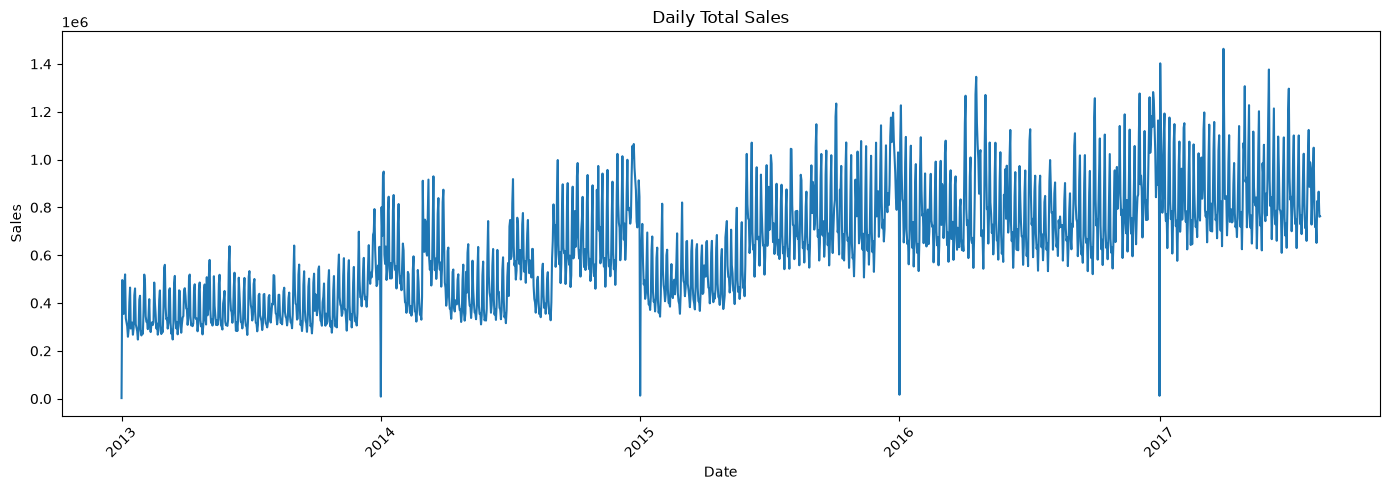

In [70]:
# Overall daily sales trend.
plt.figure(figsize=(14, 5))
plt.plot(daily_sales["date"], daily_sales["sales"])
plt.title("Daily Total Sales")
plt.xlabel("Date")
plt.ylabel("Sales")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


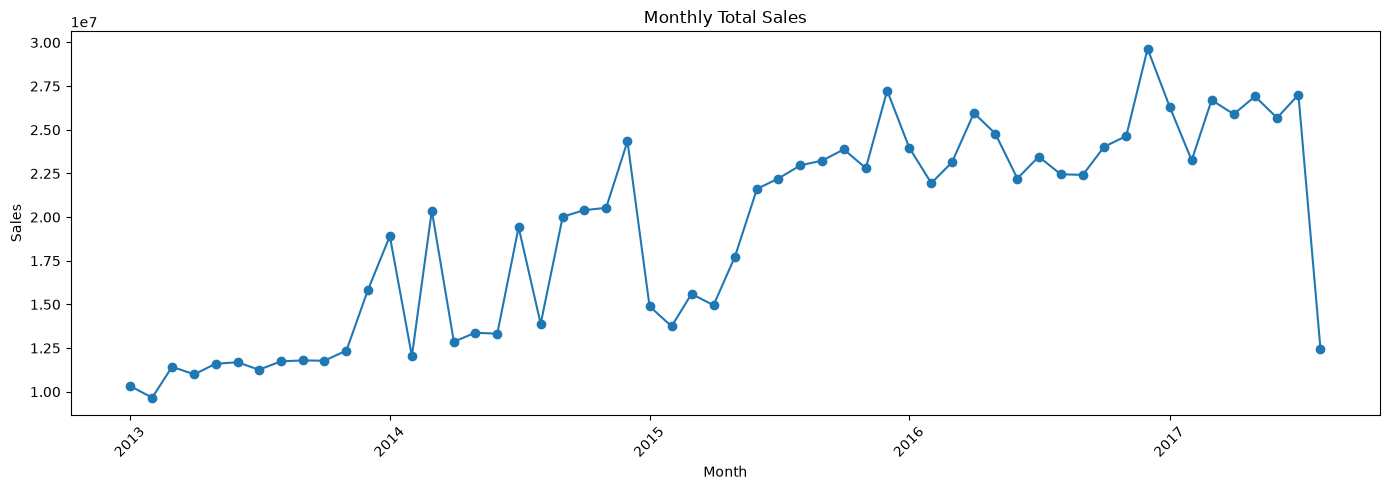

In [71]:
# Monthly sales trend.
monthly_sales = (
    train.set_index("date")["sales"]
    .resample("MS")
    .sum()
    .reset_index()
)

plt.figure(figsize=(14, 5))
plt.plot(monthly_sales["date"], monthly_sales["sales"], marker="o")
plt.title("Monthly Total Sales")
plt.xlabel("Month")
plt.ylabel("Sales")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


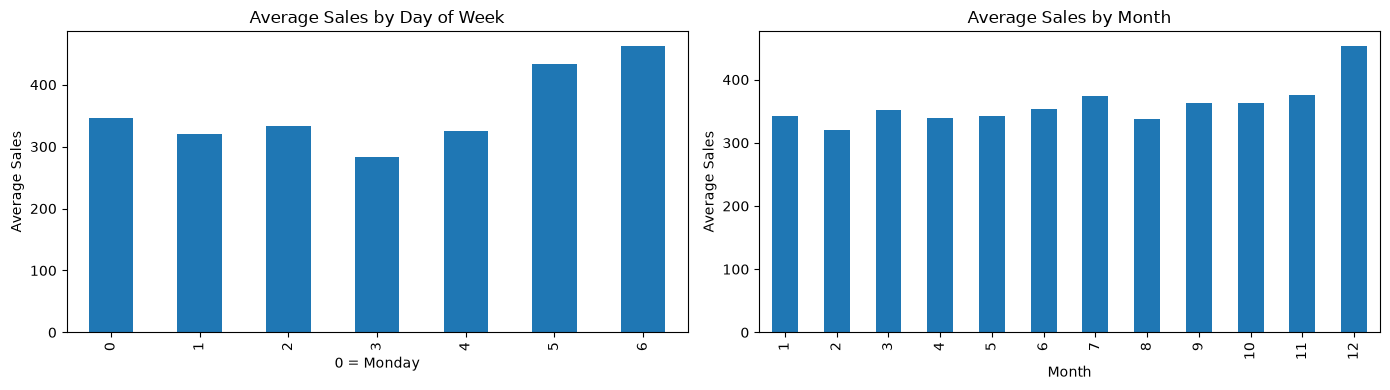

In [72]:
# Calendar patterns.
calendar_view = train.copy()
calendar_view["day_of_week"] = calendar_view["date"].dt.dayofweek
calendar_view["month"] = calendar_view["date"].dt.month

dow = calendar_view.groupby("day_of_week")["sales"].mean()
month = calendar_view.groupby("month")["sales"].mean()

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

dow.plot(kind="bar", ax=axes[0])
axes[0].set_title("Average Sales by Day of Week")
axes[0].set_xlabel("0 = Monday")
axes[0].set_ylabel("Average Sales")

month.plot(kind="bar", ax=axes[1])
axes[1].set_title("Average Sales by Month")
axes[1].set_xlabel("Month")
axes[1].set_ylabel("Average Sales")

plt.tight_layout()
plt.show()


In [73]:
# Oil price and holiday information.
print("Oil price range:")
display(oil["dcoilwtico"].describe())

print("\nHoliday types:")
display(holidays["type"].value_counts().to_frame("count"))

print("\nHoliday locales:")
display(holidays["locale"].value_counts().to_frame("count"))


Oil price range:


count   1,175.00
mean       67.71
std        25.63
min        26.19
25%        46.41
50%        53.19
75%        95.66
max       110.62
Name: dcoilwtico, dtype: float64


Holiday types:


,count
type,
Holiday,221
Event,56
Additional,51
Transfer,12
Bridge,5
Work Day,5



Holiday locales:


,count
locale,
National,174
Local,152
Regional,24


## EDA conclusion

Before moving forward, note:
- The target is `sales`.
- This is a time-series problem, so chronological order matters.
- We will not use a random train/test split.
- Lag and rolling features must be created without using future sales.
- The raw files in `data/raw` remain unchanged.
